# Ej. 1 · Entrenamiento y ejecución completos (3,5 puntos)

**Objetivo (enunciado):** completar `execution_lab.ipynb` hasta lograr un entrenamiento y una ejecución completos, con los
elementos de un entorno de RL, el orden de interacción correcto y el entrenamiento en el orden que exige el algoritmo.

### Bloques modificados respecto a `execution_lab.ipynb`

| Bloque del LAB | Cambio | Motivo | Decisión |
|---|---|---|---|
| Celda 7 · `BestExecutionEnv` | 13 funciones completadas, en `common/env.py` | El enunciado permite estructurar el código en `.py`; el notebook 00 las presenta | D-0.3 |
| Celda 3 · `DDQNAgent` | Portado a PyTorch con la misma interfaz | TF 2.15 no instala en Python ≥ 3.12 y es más lento | D-0.1 |
| Celda 9 · `TWAP` | `TWAPAgent`: compra si V ≥ T | Benchmark determinista | D-1.4 |
| Celda 12 · parámetros | Valores elegidos (abajo) | El ej. 1 no exige motivarlos | — |
| Celda 16 · llenado del buffer | 25 episodios aleatorios en lugar de `buffer_size` pasos | Recomendación de clase: llenarlo solo en parte | D-1.1 |
| Celda 18 · bucle | `protocol.train`, mismo orden de llamadas | Reutilizable en los ejercicios 2-4 | D-0.3 |
| Celda 20 · evaluación | Greedy en train y en test | Train para las figuras; test como en el LAB | — |

In [10]:
import os, sys
sys.path.insert(0, os.path.abspath("."))   # ejecutar desde notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent
pd.set_option("display.precision", 3)
%matplotlib inline

In [11]:
ASSET = "REP"                      # D-0.2
DATA = dt.load(ASSET)
train = DATA["train"]
GRID = pr.make_grid(train, n_days=3, seed=0)   # rejilla fija de evaluación (D-0.3)
print(dt.summary(DATA)); print(len(GRID), "episodios de evaluación")

{'train': {'dias': 60, 'filas_por_dia': [3177, 3178, 3179]}, 'val': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}, 'test': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}}
27 episodios de evaluación


## 1. Parámetros

Los del LAB, con la recompensa por defecto (slippage frente al VWAP del episodio). En este ejercicio no hay un objetivo de comportamiento: lo que se comprueba es que todo el circuito funciona.

In [24]:
# Agent params
epsilon, min_epsilon = 1.0, 0.02
gamma = 0.99
alpha = 1e-3
buffer_size = 50_000
batch_size = 64
hidden_neurons = 64
# Training params
nepisodes = 4000
epsilon_decay = (epsilon - min_epsilon) / (0.5 * nepisodes)   # llega al mínimo a mitad de entrenamiento
learn_after = batch_size
update_target_after = 10 * learn_after
SEED = 0

In [25]:
from types import SimpleNamespace

print(rw.Default().done(
    SimpleNamespace(vol_care=50, exec_vol=25)
))

-0.005


## 2. Entorno, agente y llenado del buffer

In [26]:
pr.set_seeds(SEED)
env = BestExecutionEnv(train, look_back=60, reward=rw.Default(), seed=SEED)
agent = DDQNAgent(env, gamma=gamma, epsilon=epsilon, alpha=alpha, batch_size=batch_size,
                  buffer_size=buffer_size, hidden_neurons=hidden_neurons, seed=SEED)
steps = pr.fill_buffer(agent, env, n_episodes=25)
print(f"buffer: {len(agent.buffer)} experiencias ({steps} pasos aleatorios)")

buffer: 12202 experiencias (12202 pasos aleatorios)


## 3. Entrenamiento

Episode 25: steps 491, rew -0.013, mse 0.0000, eps 0.99, 1s
Episode 50: steps 427, rew -0.017, mse 0.0000, eps 0.98, 1s
Episode 75: steps 423, rew -0.010, mse 0.0000, eps 0.96, 2s
Episode 100: steps 406, rew 0.004, mse 0.0000, eps 0.95, 3s
Episode 125: steps 392, rew -0.003, mse 0.0000, eps 0.94, 3s
Episode 150: steps 393, rew -0.010, mse 0.0000, eps 0.93, 4s
Episode 175: steps 361, rew -0.010, mse 0.0000, eps 0.91, 4s
Episode 200: steps 315, rew -0.024, mse 0.0000, eps 0.90, 5s
Episode 225: steps 316, rew 0.002, mse 0.0000, eps 0.89, 5s
Episode 250: steps 327, rew -0.011, mse 0.0000, eps 0.88, 6s
Episode 275: steps 326, rew -0.022, mse 0.0000, eps 0.87, 6s
Episode 300: steps 303, rew -0.001, mse 0.0000, eps 0.85, 7s
Episode 325: steps 279, rew -0.005, mse 0.0000, eps 0.84, 7s
Episode 350: steps 315, rew -0.013, mse 0.0000, eps 0.83, 7s
Episode 375: steps 320, rew -0.005, mse 0.0000, eps 0.82, 8s
Episode 400: steps 294, rew -0.018, mse 0.0000, eps 0.80, 8s
Episode 425: steps 322, rew -

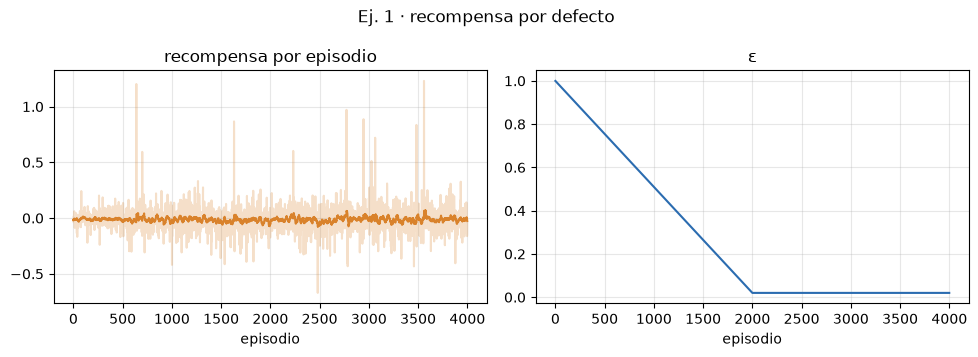

In [27]:
ep, ev = pr.train(agent, env, nepisodes, ex.LinearDecay(epsilon, min_epsilon, epsilon_decay),
                  learn_after=learn_after, update_target_after=update_target_after, log_every=25)
pr.save_df(ep, "ej1_train")
pl.plot_training(ep, title="Ej. 1 · recompensa por defecto", save="ej1_training");

## 4. Ejecución greedy

In [28]:
res = pr.evaluate(agent, train, GRID, reward=rw.Default())
pr.save_df(res, "ej1_eval_train")
agent.save(pr.MODELS / "ej1_ddqn.pt")
pd.DataFrame({"DDQN (recompensa por defecto)": pr.summarize(res),
              "TWAP determinista": pr.summarize(pr.load_df("00_twap_grid"))})

,DDQN (recompensa por defecto),TWAP determinista
completed_mean,1.000,1.000
completed_std,0.000,0.000
pending_mean,0.000,0.000
pending_std,0.000,0.000
t_fin_mean,0.100,0.981
t_fin_std,0.021,0.005
max_err_mean,44.703,0.900
max_err_std,11.262,0.021
mean_err_mean,22.351,0.437
mean_err_std,5.631,0.017


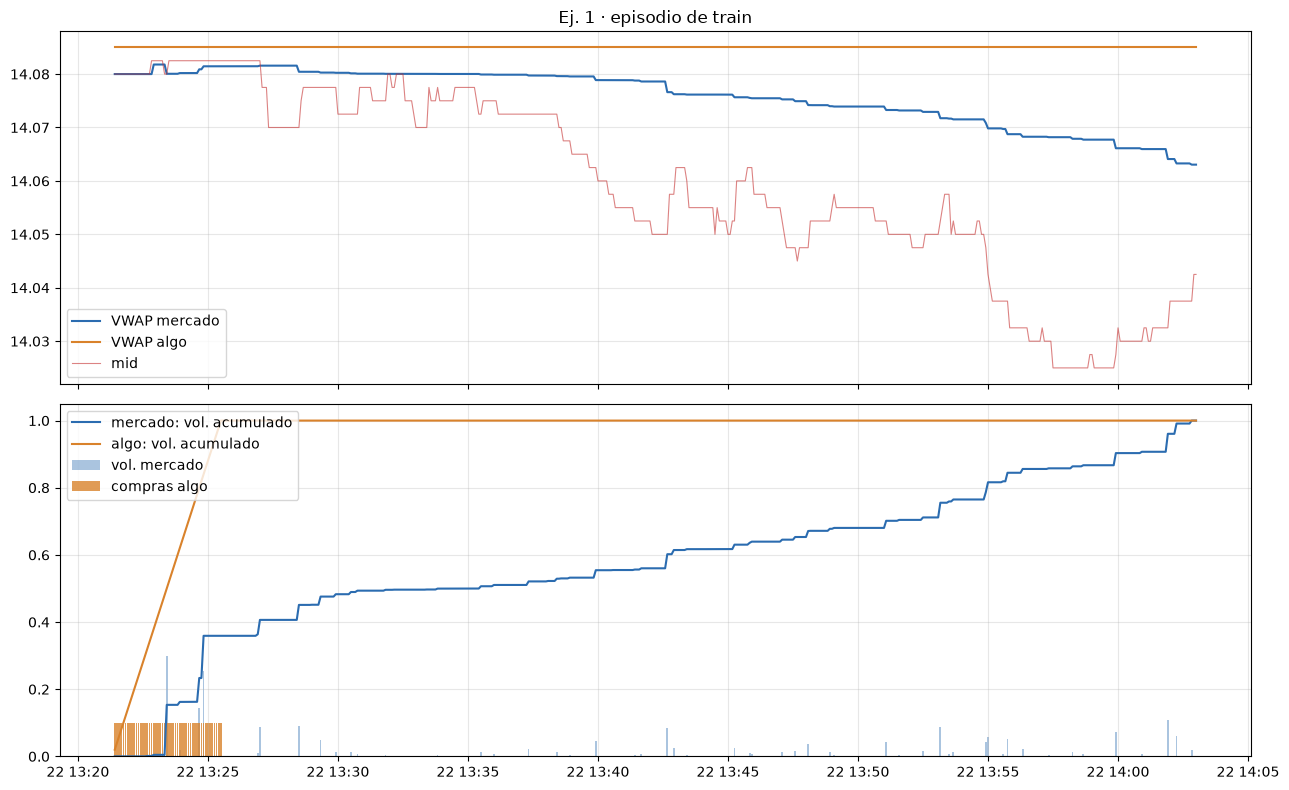

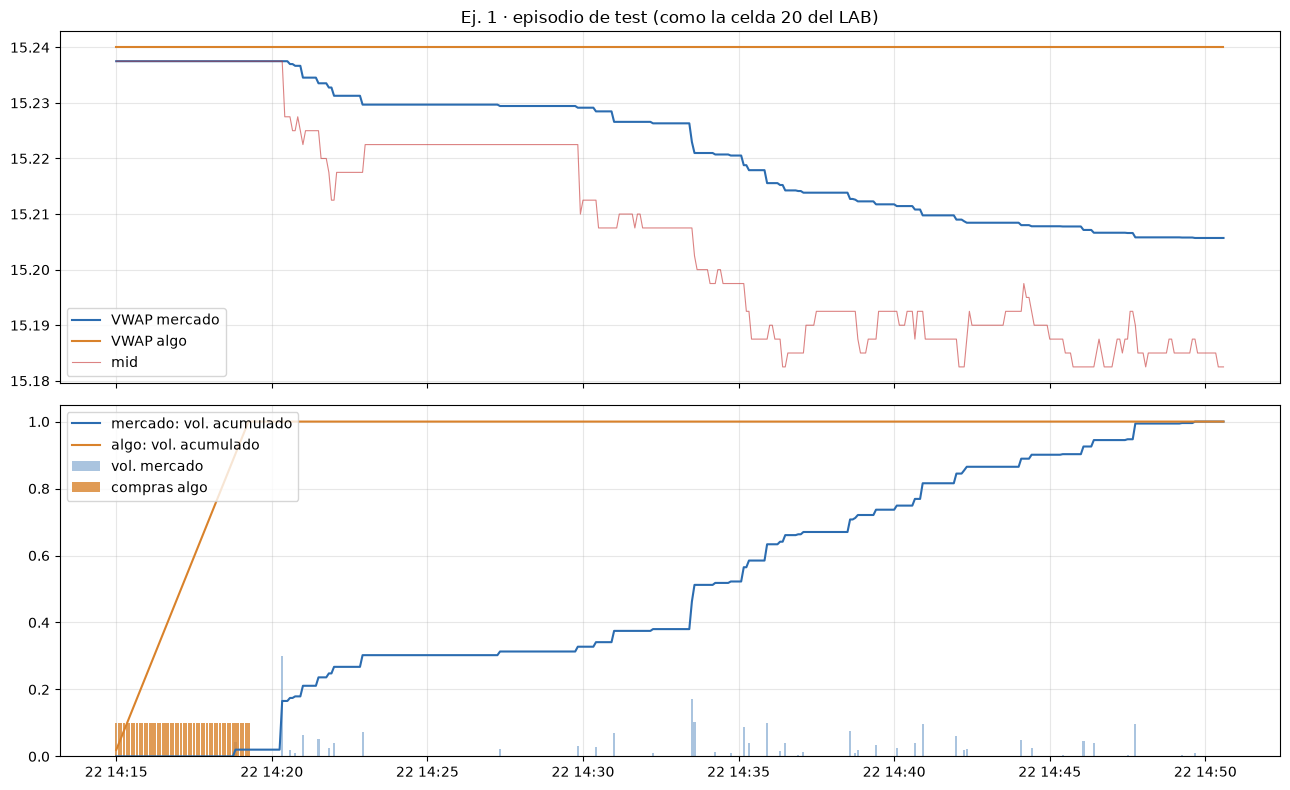

In [29]:
env_tr = BestExecutionEnv(train, seed=1)
agent.env = env_tr; agent.set_trainable(False)
pr.run_episode(env_tr, agent, GRID[4])
pl.plot_results(env_tr, title="Ej. 1 · episodio de train", save="ej1_episodio_train");
env_te = BestExecutionEnv(DATA["test"], seed=1)
agent.env = env_te
pr.run_episode(env_te, agent)
pl.plot_results(env_te, title="Ej. 1 · episodio de test (como la celda 20 del LAB)", save="ej1_episodio_test");

## 5. Conclusión

El circuito completo funciona: generación de episodios, interacción, buffer, aprendizaje Double DQN con red objetivo y
ejecución greedy. Con la recompensa por defecto el agente **no** tiene motivo para repartir las compras: premia comprar por
debajo del VWAP de todo el episodio, que no puede anticipar con [T, V]. Por eso el ej. 2 cambia la recompensa.